# X-Wines: Collaborative Filtering (Person C — Tasks 3 and 5)

**Question:** beyond "this user rates high" and "this wine is rated high", do users' rating histories contain
*personal taste* that collaborative filtering can learn?

Models, all from the course recommender-systems slides:

| Family | Model | Slides |
|---|---|---|
| Baselines | global / user / item mean, regularized bias model $\mu + b_u + b_i$ | rating prediction |
| Similarity-based | item-to-item CF with Jaccard, cosine and Pearson similarity | collaborative filtering |
| Latent factors | $\mu + b_u + b_i + p_u \cdot q_i$, our own alternating least squares (ALS) | latent-factor models |
| Latent factors (library) | Surprise SVD (stochastic gradient descent) | Surprise code example |
| Implicit-feedback extension | Surprise SVD++ (which wines a user chose to rate) | extensions of latent-factor models |

Protocol (shared with the rest of the project; see `docs/evaluation_protocol.md`): the verified **chronological**
split of the Slim edition, fit on train, tune on validation, score test once for the validation-selected
configuration of each model. RMSE is primary, MAE secondary, predictions clipped to [1, 5].
All model code is in `src/cf.py`; findings are summarized in `reports/C_findings.md`.

In [1]:
from pathlib import Path
import sys, os, time
ROOT = Path.cwd()
if not (ROOT/'src/cf.py').exists(): ROOT = ROOT.parent
assert (ROOT/'src/cf.py').exists(), 'Run from repo root or notebooks/'
sys.path.insert(0, str(ROOT))
os.environ.setdefault('MPLCONFIGDIR', str(ROOT/'.cache/matplotlib'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import pearsonr
from src.pipeline import load_prepared_splits, score_predictions
from src.experiments import (SEED, metrics, baseline_predictions, cluster_bootstrap,
                             error_slices, join_metadata, FeatureProbe)
from src.cf import (BiasBaseline, ItemCF, ALSMF, SurpriseMF, SIMILARITIES, evaluate,
                    mf_epoch_curve, neighbour_type_agreement, prediction_frame)

REPORTS = ROOT/'reports'; FIGURES = REPORTS/'figures'; OUTPUTS = ROOT/'outputs'
for folder in (FIGURES, OUTPUTS): folder.mkdir(parents=True, exist_ok=True)
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
INK, MUTED = '#2b2b2b', '#8a8a85'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'font.size': 10, 'axes.edgecolor': MUTED, 'axes.grid': True,
                     'grid.color': '#e6e5df', 'grid.linewidth': 0.6, 'lines.linewidth': 2})

wines, parts = load_prepared_splits(ROOT, 'chronological')
train, validation, test = parts['train'], parts['validation'], parts['test']
print({k: len(v) for k, v in parts.items()}, '| seed', SEED)

{'train': 120000, 'validation': 15000, 'test': 15000} | seed 258


## 3.1 Baselines

The repo's references are the global, user and item means (shrinkage 10) and ridge regression on one-hot
user/wine IDs (a bias model). Our `BiasBaseline` fits the same additive model, $\hat r = \mu + b_u + b_i$,
but with **separate** regularization for users and wines, solved by alternating exact updates
(each update minimizes the regularized squared error for one block with the other fixed).

In [2]:
bias_rows = []
for reg_user in [1, 2, 5, 10, 20]:
    for reg_item in [1, 2, 5, 10, 20]:
        bias_rows.append(evaluate(BiasBaseline(reg_user, reg_item), train, validation, 'bias',
                                  reg_user=reg_user, reg_item=reg_item))
bias_grid = pd.DataFrame(bias_rows)
bias_grid.to_csv(REPORTS/'C_bias_grid.csv', index=False)
best_bias = bias_grid.loc[bias_grid.val_rmse.idxmin()]
print(f"Best bias model: reg_user={best_bias.reg_user:g}, reg_item={best_bias.reg_item:g}, "
      f"validation RMSE {best_bias.val_rmse:.4f}")
display(bias_grid.pivot(index='reg_user', columns='reg_item', values='val_rmse').round(4))

Best bias model: reg_user=5, reg_item=2, validation RMSE 0.4505


reg_item,1,2,5,10,20
reg_user,,,,,
1,0.4589,0.4588,0.4592,0.4604,0.4631
2,0.4534,0.4533,0.4536,0.4547,0.4573
5,0.4506,0.4505,0.4507,0.4516,0.4538
10,0.4538,0.4536,0.4537,0.4544,0.4562
20,0.4605,0.4602,0.4602,0.4607,0.4621


## 3.2 Item-to-item collaborative filtering

Prediction for user $u$ and wine $i$, using the $k$ wines $j$ the user rated in training that are most similar
to $i$:

$$\hat r_{ui} = \underbrace{\mu + b_u + b_i}_{\text{bias baseline}} + \frac{\sum_j s_{ij}\,(r_{uj} - \mu - b_u - b_j)}{\sum_j s_{ij} + d}$$

- $s_{ij}$ is Jaccard (overlap of the user sets), cosine (rating vectors) or Pearson (co-rating users only),
  multiplied by $n_{ij}/(n_{ij}+50)$ to distrust wines that share few raters.
- $d$ (damping) shrinks the neighbour correction when neighbours are few or weak. $d = 0$ is the textbook
  weighted average.
- Similarities are computed from training ratings only. Users or wines without training history fall back to the
  bias baseline.

In [3]:
bias_model = BiasBaseline(best_bias.reg_user, best_bias.reg_item)
cf_rows = []
for similarity in SIMILARITIES:
    start = time.perf_counter()
    cf = ItemCF(similarity, baseline=bias_model).fit(train)
    fit_seconds = time.perf_counter() - start
    for k in [10, 20, 50]:
        for damping in [0, 1, 5, 20]:
            cf.k, cf.damping = k, damping
            pred = cf.predict(validation)
            cf_rows.append(dict(model='item_cf', similarity=similarity, k=k, damping=damping,
                                fit_seconds=fit_seconds,
                                **{f'val_{m}': v for m, v in metrics(validation.Rating, pred).items()},
                                neighbour_share=cf.neighbour_rows/len(validation)))
cf_grid = pd.DataFrame(cf_rows)
cf_grid.to_csv(REPORTS/'C_itemcf_grid.csv', index=False)
best_cf = cf_grid.loc[cf_grid.val_rmse.idxmin()]
print(f"Best item CF: {best_cf.similarity}, k={best_cf.k}, damping={best_cf.damping}, "
      f"validation RMSE {best_cf.val_rmse:.4f} (bias baseline {best_bias.val_rmse:.4f})")
display(cf_grid.pivot_table(index=['similarity', 'k'], columns='damping', values='val_rmse').round(4))

Best item CF: cosine, k=10, damping=1, validation RMSE 0.4496 (bias baseline 0.4505)


damping            0       1       5       20
similarity k                                 
cosine     10  0.4938  0.4496  0.4501  0.4504
           20  0.4932  0.4496  0.4501  0.4504
           50  0.4932  0.4496  0.4501  0.4504
jaccard    10  0.4950  0.4497  0.4503  0.4504
           20  0.4943  0.4497  0.4503  0.4504
           50  0.4943  0.4497  0.4503  0.4504
pearson    10  0.4954  0.4515  0.4500  0.4503
           20  0.4948  0.4514  0.4499  0.4503
           50  0.4948  0.4514  0.4499  0.4503

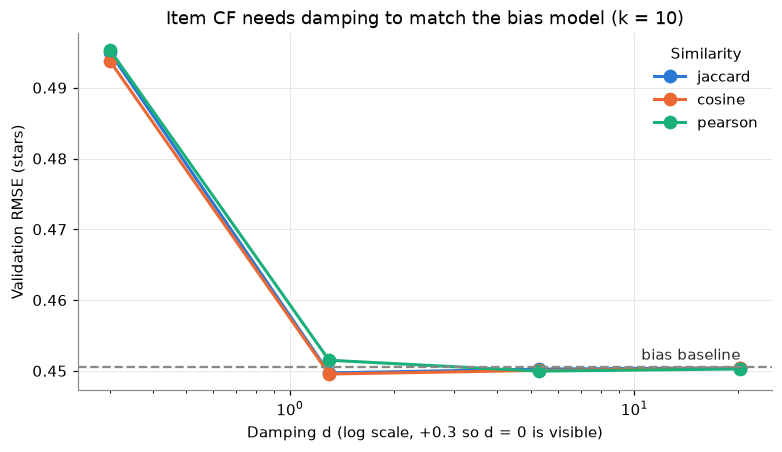

In [4]:
fig, ax = plt.subplots(figsize=(7, 4), layout='constrained')
for color, similarity in zip(SERIES, SIMILARITIES):
    s = cf_grid[(cf_grid.similarity == similarity) & (cf_grid.k == best_cf.k)].sort_values('damping')
    ax.plot(s.damping + 0.3, s.val_rmse, marker='o', markersize=8, color=color, label=similarity)
ax.axhline(best_bias.val_rmse, color=MUTED, linestyle='--', linewidth=1.5)
ax.annotate('bias baseline', (20.3, best_bias.val_rmse), xytext=(0, 5), textcoords='offset points',
            ha='right', color=INK)
ax.set(xscale='log', xlabel='Damping d (log scale, +0.3 so d = 0 is visible)',
       ylabel='Validation RMSE (stars)', title=f'Item CF needs damping to match the bias model (k = {best_cf.k})')
ax.legend(title='Similarity', frameon=False)
fig.savefig(FIGURES/'C_itemcf_damping.png', bbox_inches='tight'); plt.show()

## 3.3 Latent-factor model (our ALS implementation)

$$\hat r_{ui} = \mu + b_u + b_i + p_u \cdot q_i$$

**Optimization.** We minimize squared error plus $\lambda(\lVert p_u\rVert^2 + \lVert q_i\rVert^2)$ and the
bias penalties selected in 3.1, by **alternating least squares**: with every $q_i$ fixed, each user's
$(b_u, p_u)$ is an exact ridge regression; then the roles swap. Each half-step cannot increase the objective, so
there is no learning rate to tune and training error falls monotonically. Factors start from $N(0, 0.1^2)$ with
seed 258. With very strong $\lambda$ the factors shrink to zero and the model becomes exactly the bias baseline.

We sweep the number of latent dimensions $k$ and the regularization $\lambda$ (10 alternating sweeps).

In [5]:
als_rows = []
for k in [1, 2, 4, 8, 16, 32, 64]:
    for reg in [5, 8, 11, 14, 20, 30]:
        als_rows.append(evaluate(ALSMF(k, reg, reg_user_bias=best_bias.reg_user, reg_item_bias=best_bias.reg_item,
                                       n_iter=10), train, validation, 'als_mf', k=k, reg=reg))
als_grid = pd.DataFrame(als_rows)
als_grid.to_csv(REPORTS/'C_als_grid.csv', index=False)
best_als = als_grid.loc[als_grid.val_rmse.idxmin()]
print(f"Best ALS MF: k={best_als.k:g}, lambda={best_als.reg:g}, validation RMSE {best_als.val_rmse:.4f}; "
      f"fit {best_als.fit_seconds:.1f}s")
display(als_grid.pivot(index='k', columns='reg', values='val_rmse').round(4))

Best ALS MF: k=8, lambda=11, validation RMSE 0.4502; fit 3.7s


reg,5,8,11,14,20,30
k,,,,,,
1,0.4569,0.4520,0.4505,0.4505,0.4505,0.4505
2,0.4612,0.4526,0.4505,0.4505,0.4505,0.4505
4,0.4628,0.4525,0.4504,0.4505,0.4505,0.4505
8,0.4647,0.4523,0.4502,0.4505,0.4505,0.4505
16,0.4637,0.4521,0.4504,0.4505,0.4505,0.4505
32,0.4579,0.4515,0.4503,0.4505,0.4505,0.4505
64,0.4551,0.4509,0.4502,0.4505,0.4505,0.4505


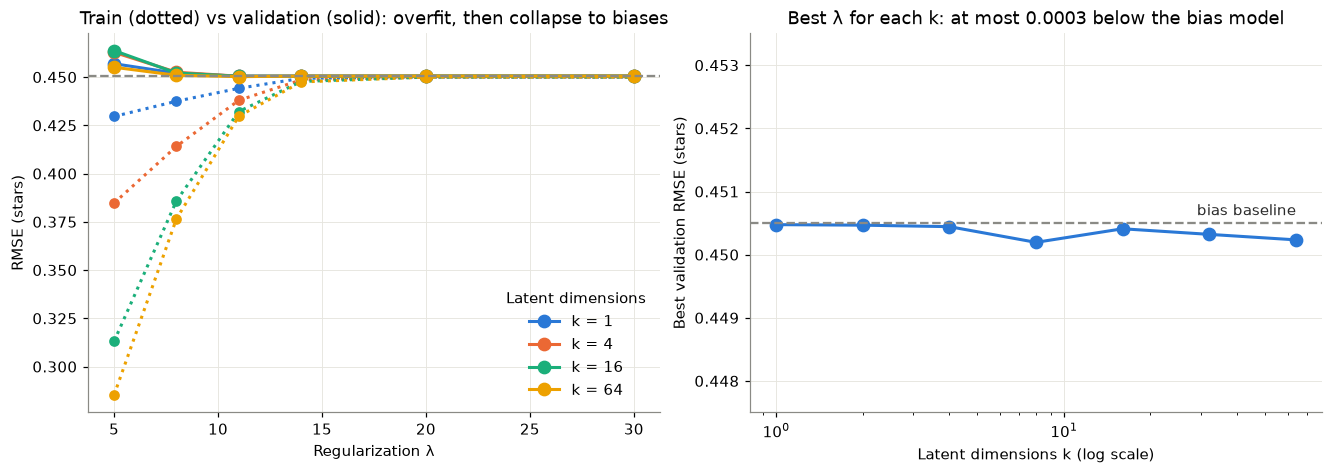

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2), layout='constrained')
for color, k in zip(SERIES, [1, 4, 16, 64]):
    s = als_grid[als_grid.k == k].sort_values('reg')
    ax[0].plot(s.reg, s.train_rmse, color=color, linestyle=':', marker='o', markersize=6)
    ax[0].plot(s.reg, s.val_rmse, color=color, marker='o', markersize=8, label=f'k = {k}')
ax[0].axhline(best_bias.val_rmse, color=MUTED, linestyle='--', linewidth=1.5)
ax[0].set(xlabel='Regularization λ', ylabel='RMSE (stars)',
          title='Train (dotted) vs validation (solid): overfit, then collapse to biases')
ax[0].legend(title='Latent dimensions', frameon=False)
s = als_grid.loc[als_grid.groupby('k').val_rmse.idxmin()]
ax[1].plot(s.k, s.val_rmse, color=SERIES[0], marker='o', markersize=8)
ax[1].axhline(best_bias.val_rmse, color=MUTED, linestyle='--', linewidth=1.5)
ax[1].annotate('bias baseline', (s.k.max(), best_bias.val_rmse), xytext=(0, 5), textcoords='offset points',
               ha='right', color=INK)
ax[1].set(xscale='log', xlabel='Latent dimensions k (log scale)', ylabel='Best validation RMSE (stars)',
          ylim=(best_bias.val_rmse - 0.003, best_bias.val_rmse + 0.003),
          title='Best λ for each k: at most 0.0003 below the bias model')
fig.savefig(FIGURES/'C_als_k_lambda.png', bbox_inches='tight'); plt.show()

**Learning curves.** Training error per ALS sweep for three regularization levels at $k = 16$:
weak regularization overfits (training error keeps falling, validation rises), strong regularization shrinks the
factors to zero (the model becomes the bias baseline).

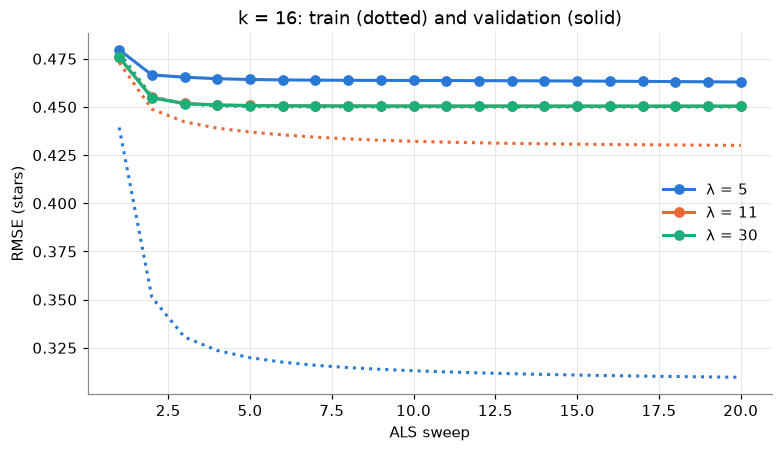

In [7]:
curves = []
for reg in [5, 11, 30]:
    model = ALSMF(16, reg, reg_user_bias=best_bias.reg_user, reg_item_bias=best_bias.reg_item,
                  n_iter=20, track=validation).fit(train)
    curves.append(pd.DataFrame(model.curve).assign(reg=reg))
curves = pd.concat(curves, ignore_index=True)
curves.to_csv(REPORTS/'C_als_learning_curves.csv', index=False)
fig, ax = plt.subplots(figsize=(7, 4), layout='constrained')
for color, (reg, g) in zip(SERIES, curves.groupby('reg')):
    ax.plot(g.iteration, g.train_rmse, color=color, linestyle=':')
    ax.plot(g.iteration, g.val_rmse, color=color, marker='o', markersize=6, label=f'λ = {reg}')
ax.set(xlabel='ALS sweep', ylabel='RMSE (stars)', title='k = 16: train (dotted) and validation (solid)')
ax.legend(frameon=False)
fig.savefig(FIGURES/'C_als_learning_curves.png', bbox_inches='tight'); plt.show()

## 3.4 Library comparison: Surprise SVD (SGD) and SVD++

Surprise fits the same model by **stochastic gradient descent** (learning rate 0.005, one regularization
`reg_all` for biases and factors). SVD++ adds implicit feedback:
$\hat r_{ui} = \mu + b_u + b_i + q_i \cdot (p_u + |N(u)|^{-1/2}\sum_{j \in N(u)} y_j)$, where $N(u)$ is the set of
wines $u$ rated in training. Surprise visits ratings in a fixed order from a seeded start, so the epoch curve
below is exact (a fit with $e$ epochs equals the first $e$ epochs of a longer fit).

In [8]:
svd_rows = []
for k in [4, 16, 64]:
    for reg in [0.02, 0.05, 0.1]:
        for epochs in [20, 50]:
            svd_rows.append(evaluate(SurpriseMF(k, reg, 0.005, epochs), train, validation, 'surprise_svd',
                                     k=k, reg=reg, epochs=epochs))
for k in [4, 16]:
    for reg in [0.02, 0.05, 0.1]:
        svd_rows.append(evaluate(SurpriseMF(k, reg, 0.005, 20, algo='svdpp'), train, validation,
                                 'surprise_svdpp', k=k, reg=reg, epochs=20))
svd_grid = pd.DataFrame(svd_rows)
svd_grid.to_csv(REPORTS/'C_surprise_grid.csv', index=False)
best_svd = svd_grid[svd_grid.model == 'surprise_svd'].sort_values('val_rmse').iloc[0]
best_svdpp = svd_grid[svd_grid.model == 'surprise_svdpp'].sort_values('val_rmse').iloc[0]
display(svd_grid.sort_values('val_rmse')[['model', 'k', 'reg', 'epochs', 'train_rmse', 'val_rmse',
                                          'fit_seconds']].round(4).head(10))

,model,k,reg,epochs,train_rmse,val_rmse,fit_seconds
18,surprise_svdpp,4,0.02,20,0.4537,0.4504,1.8020
19,surprise_svdpp,4,0.05,20,0.4563,0.4505,1.9850
0,surprise_svd,4,0.02,20,0.4542,0.4505,1.0880
2,surprise_svd,4,0.05,20,0.4564,0.4505,0.9941
22,surprise_svdpp,16,0.05,20,0.4519,0.4509,2.9267
8,surprise_svd,16,0.05,20,0.4524,0.4510,1.1083
21,surprise_svdpp,16,0.02,20,0.4449,0.4510,2.9121
20,surprise_svdpp,4,0.10,20,0.4597,0.4513,1.5931
4,surprise_svd,4,0.10,20,0.4597,0.4513,0.9990
6,surprise_svd,16,0.02,20,0.4477,0.4515,1.0437


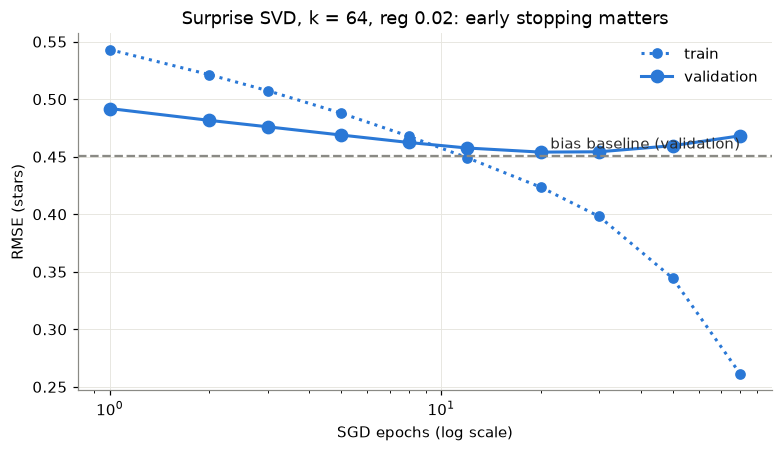

In [9]:
sgd_curve = mf_epoch_curve(train, validation, [1, 2, 3, 5, 8, 12, 20, 30, 50, 80],
                           n_factors=64, reg=0.02, lr=0.005)
sgd_curve.to_csv(REPORTS/'C_sgd_epoch_curve.csv', index=False)
fig, ax = plt.subplots(figsize=(7, 4), layout='constrained')
ax.plot(sgd_curve.epochs, sgd_curve.train_rmse, color=SERIES[0], linestyle=':', marker='o', markersize=6, label='train')
ax.plot(sgd_curve.epochs, sgd_curve.val_rmse, color=SERIES[0], marker='o', markersize=8, label='validation')
ax.axhline(best_bias.val_rmse, color=MUTED, linestyle='--', linewidth=1.5)
ax.annotate('bias baseline (validation)', (80, best_bias.val_rmse), xytext=(0, 5), textcoords='offset points',
            ha='right', color=INK)
ax.set(xscale='log', xlabel='SGD epochs (log scale)', ylabel='RMSE (stars)',
       title='Surprise SVD, k = 64, reg 0.02: early stopping matters')
ax.legend(frameon=False)
fig.savefig(FIGURES/'C_sgd_epoch_curve.png', bbox_inches='tight'); plt.show()

## 3.5 Final test evaluation

Each model uses its validation-selected configuration, fitted on the training partition only, and is scored once
on the chronological test. Paired 95% user-cluster bootstrap intervals (2,000 resamples, the repo's
`cluster_bootstrap`) compare each model with the bias baseline; negative ΔRMSE favours the model.

In [10]:
final = {
    'bias': BiasBaseline(best_bias.reg_user, best_bias.reg_item),
    'item_cf': ItemCF(best_cf.similarity, int(best_cf.k), damping=best_cf.damping,
                      baseline=BiasBaseline(best_bias.reg_user, best_bias.reg_item)),
    'als_mf': ALSMF(int(best_als.k), best_als.reg, reg_user_bias=best_bias.reg_user,
                    reg_item_bias=best_bias.reg_item, n_iter=10),
    'surprise_svd': SurpriseMF(int(best_svd.k), best_svd.reg, 0.005, int(best_svd.epochs)),
    'surprise_svdpp': SurpriseMF(int(best_svdpp.k), best_svdpp.reg, 0.005, int(best_svdpp.epochs), algo='svdpp'),
}
settings = {
    'bias': f"reg_user={best_bias.reg_user:g}, reg_item={best_bias.reg_item:g}",
    'item_cf': f"{best_cf.similarity}, k={best_cf.k}, damping={best_cf.damping}",
    'als_mf': f"k={best_als.k:g}, lambda={best_als.reg:g}",
    'surprise_svd': f"k={best_svd.k:g}, reg={best_svd.reg:g}, epochs={best_svd.epochs:g}",
    'surprise_svdpp': f"k={best_svdpp.k:g}, reg={best_svdpp.reg:g}, epochs={best_svdpp.epochs:g}",
}
test_pred, val_pred, fit_time = {}, {}, {}
for name, model in final.items():
    start = time.perf_counter(); model.fit(train); fit_time[name] = time.perf_counter() - start
    test_pred[name] = model.predict(test); val_pred[name] = model.predict(validation)
    prediction_frame(validation, val_pred[name]).to_csv(OUTPUTS/f'C_{name}_validation.csv', index=False)
    prediction_frame(test, test_pred[name]).to_csv(OUTPUTS/f'C_{name}_test.csv', index=False)

# Repo references, recomputed on the same rows.
reference = baseline_predictions(train, test)
probe = FeatureProbe(['UserID', 'WineID'], 10.).fit(join_metadata(train, wines))
reference['ridge_ids (repo)'] = probe.predict(join_metadata(test, wines))

rows = []
for name, pred in {**reference, **test_pred}.items():
    row = dict(model=name, settings=settings.get(name, 'repo reference'), **metrics(test.Rating, pred))
    if name in final:
        row['fit_seconds'] = fit_time[name]
        row.update({f'vs_bias_{k}': v for k, v in
                    cluster_bootstrap(test, test_pred['bias'], pred).items() if k in ('delta_rmse', 'ci_low', 'ci_high')})
    rows.append(row)
results = pd.DataFrame(rows)
results.to_csv(REPORTS/'C_test_metrics.csv', index=False)
display(results.round(4))
# The scorer used by the whole team must agree with these numbers.
check = score_predictions(test, pd.read_csv(OUTPUTS/'C_als_mf_test.csv'))
assert abs(check['rmse'] - results.set_index('model').loc['als_mf', 'rmse']) < 1e-12
print('Shared scorer agrees:', {k: round(v, 4) if isinstance(v, float) else v for k, v in check.items()})

,model,settings,rmse,mae,fit_seconds,vs_bias_delta_rmse,vs_bias_ci_low,vs_bias_ci_high
0,global,repo reference,0.6123,0.4932,NaN,NaN,NaN,NaN
1,user_mean,repo reference,0.5878,0.4649,NaN,NaN,NaN,NaN
2,item_mean,repo reference,0.4785,0.3682,NaN,NaN,NaN,NaN
3,ridge_ids (repo),repo reference,0.4493,0.3401,NaN,NaN,NaN,NaN
4,bias,"reg_user=5, reg_item=2",0.4457,0.3356,0.0262,0.0000,0.0000,0.0000
5,item_cf,"cosine, k=10, damping=1",0.4446,0.3342,0.8149,-0.0011,-0.0017,-0.0005
6,als_mf,"k=8, lambda=11",0.4460,0.3358,4.8464,0.0003,-0.0001,0.0007
7,surprise_svd,"k=4, reg=0.02, epochs=20",0.4457,0.3350,1.2132,-0.0001,-0.0010,0.0009
8,surprise_svdpp,"k=4, reg=0.02, epochs=20",0.4457,0.3351,2.5496,-0.0000,-0.0010,0.0009


Shared scorer agrees: {'rows': 15000, 'clipped': 0, 'rmse': 0.446, 'mae': 0.3358}


**Sensitivity: random split.** The chronological test is later in time and its mean rating is higher
(3.99 vs 3.78 in train). To check that our conclusion is not only a time-drift effect, we refit the same
selected configurations on the repo's random user–wine split (hyperparameters are *not* re-tuned).

In [11]:
_, random_parts = load_prepared_splits(ROOT, 'random')
r_train, r_test = random_parts['train'], random_parts['test']
random_rows = []
random_pred = {}
for name, model in final.items():
    random_pred[name] = model.fit(r_train).predict(r_test)
for name, pred in random_pred.items():
    random_rows.append(dict(model=name, **metrics(r_test.Rating, pred),
                            **{f'vs_bias_{k}': v for k, v in cluster_bootstrap(
                                r_test, random_pred['bias'], pred).items() if k in ('delta_rmse', 'ci_low', 'ci_high')}))
random_results = pd.DataFrame(random_rows)
random_results.to_csv(REPORTS/'C_random_test_metrics.csv', index=False)
display(random_results.round(4))
# Refit the chronological models so later cells use them.
for model in final.values(): model.fit(train)

,model,rmse,mae,vs_bias_delta_rmse,vs_bias_ci_low,vs_bias_ci_high
0,bias,0.4706,0.3445,0.0000,0.0000,0.0000
1,item_cf,0.4687,0.3427,-0.0019,-0.0025,-0.0013
2,als_mf,0.4707,0.3446,0.0002,-0.0002,0.0005
3,surprise_svd,0.4760,0.3480,0.0054,0.0045,0.0063
4,surprise_svdpp,0.4758,0.3478,0.0053,0.0044,0.0061


## 3.6 Scaling

Fit time on 25%, 50% and 100% of the Slim training ratings, then a back-of-envelope extrapolation to the
Full edition (21,013,536 ratings, 1,056,079 users, 100,646 wines, as published by the dataset authors; not
measured here). Each model is extrapolated by what actually drives its cost: the bias model and Surprise's SGD make
passes over the ratings; our ALS solves one small system per user and per wine (its time barely changes when only
the number of ratings grows); item CF stores a dense wine × wine similarity matrix, which is the real
obstacle at Full scale (it would need a sparse top-neighbour index instead).

In [12]:
scale_rows = []
rng = np.random.default_rng(SEED)
for fraction in [0.25, 0.5, 1.0]:
    sub = train.iloc[np.sort(rng.permutation(len(train))[:int(fraction*len(train))])]
    for name, make in [('bias', lambda: BiasBaseline(best_bias.reg_user, best_bias.reg_item)),
                       ('item_cf', lambda: ItemCF(best_cf.similarity, int(best_cf.k), damping=best_cf.damping)),
                       ('als_mf k=16', lambda: ALSMF(16, 11, n_iter=10)),
                       ('surprise_svd k=16', lambda: SurpriseMF(16, 0.05, 0.005, 20))]:
        start = time.perf_counter(); make().fit(sub)
        scale_rows.append(dict(model=name, ratings=len(sub), users=sub.UserID.nunique(),
                               fit_seconds=time.perf_counter() - start))
scaling = pd.DataFrame(scale_rows)
scaling.to_csv(REPORTS/'C_scaling.csv', index=False)
display(scaling.pivot(index='model', columns='ratings', values='fit_seconds').round(2))

FULL_RATINGS, FULL_USERS, FULL_WINES = 21_013_536, 1_056_079, 100_646
factor = FULL_RATINGS / len(train)
entity_factor = (FULL_USERS + FULL_WINES) / (train.UserID.nunique() + train.WineID.nunique())
slim_time = scaling[scaling.ratings == len(train)].set_index('model').fit_seconds
# What drives each model's cost (from the timings above):
# bias and Surprise SGD: one pass over the ratings -> scale with ratings.
# our ALS: one small k x k solve per user and per wine (a Python loop) -> scales with users + wines.
# item CF: dense wine x wine similarity -> memory grows with wines^2 (see table below).
full_time = pd.Series({
    'bias': slim_time['bias'] * factor,
    'surprise_svd k=16': slim_time['surprise_svd k=16'] * factor,
    'als_mf k=16': slim_time['als_mf k=16'] * entity_factor,
    'item_cf': np.nan,
})
memory = pd.Series({
    'dense user x wine matrix (float64)': FULL_USERS * FULL_WINES * 8,
    'dense wine x wine similarity (float64)': FULL_WINES**2 * 8,
    'MF parameters, k = 16 (float64)': (FULL_USERS + FULL_WINES) * 17 * 8,
    'sparse ratings (CSR: value + column + row pointer)': FULL_RATINGS * 12 + FULL_USERS * 8,
}) / 1e9
print(f'Full has {factor:.0f}x the Slim training ratings and {entity_factor:.0f}x the users + wines.')
print('Extrapolated fit time in minutes (item CF: not feasible as a dense similarity matrix, see memory):')
display((full_time / 60).round(1).rename('minutes (extrapolated)'))
display(memory.round(2).rename('GB'))

ratings,30000,60000,120000
model,,,
als_mf k=16,3.78,4.27,4.31
bias,0.01,0.02,0.03
item_cf,0.70,0.87,0.86
surprise_svd k=16,0.26,0.66,1.57


Full has 175x the Slim training ratings and 102x the users + wines.
Extrapolated fit time in minutes (item CF: not feasible as a dense similarity matrix, see memory):


bias                 0.1
surprise_svd k=16    4.6
als_mf k=16          7.3
item_cf              NaN
Name: minutes (extrapolated), dtype: float64

dense user x wine matrix (float64)                    850.32
dense wine x wine similarity (float64)                 81.04
MF parameters, k = 16 (float64)                         0.16
sparse ratings (CSR: value + column + row pointer)      0.26
Name: GB, dtype: float64

## 3.7 Noise, sparsity and missing data

- **Rating noise.** Ratings are half-stars from 1 to 5 and highly concentrated (most are 3.5–4.5). Even a
  perfect taste model cannot remove within-user rating inconsistency. The bias baseline's residual RMSE on
  training data is shown below.
- **Sparsity.** 98.6% of user–wine pairs are unobserved; the median user has 10 training ratings. A latent
  vector learned from 10 noisy ratings is weakly identified, which is why regularization must be strong.
- **New users.** Chronological test rows whose user never appears in training cannot be personalized; every CF
  model falls back to $\mu + b_i$.
- **Time drift.** The test period is later and rated higher, so all ID-based models under-predict on average.
  This is a bias the CF models cannot fix; the time features in the repo's ridge model and Person D's work address it.
- **Selection bias.** Users choose what to rate (and likely choose wines they expect to like), so the observed
  ratings are not a random sample of tastes.

Bias-model residual RMSE on TRAIN: 0.4500 stars; share of ratings in [3.5, 4.5]: 73.5%
Test rows with a user unseen in training: 6.6%


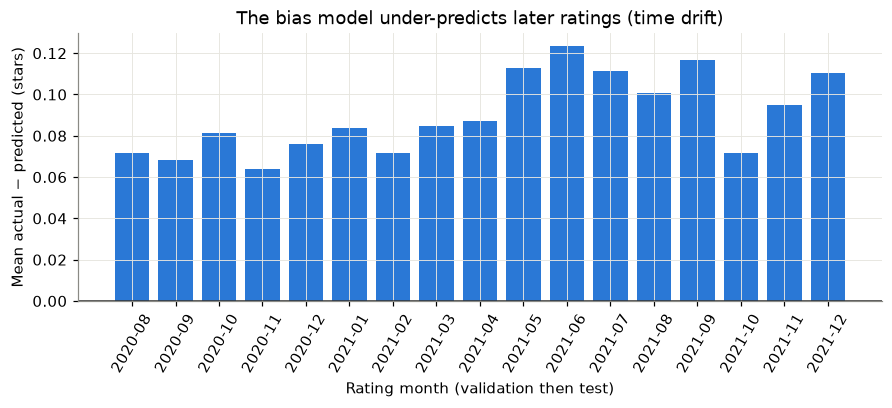

In [13]:
res_train = train.Rating - final['bias'].predict(train)
print(f"Bias-model residual RMSE on TRAIN: {np.sqrt((res_train**2).mean()):.4f} stars; "
      f"share of ratings in [3.5, 4.5]: {train.Rating.between(3.5, 4.5).mean():.1%}")
known_user = test.UserID.isin(train.UserID)
print(f"Test rows with a user unseen in training: {(~known_user).mean():.1%}")
drift = pd.DataFrame({'month': pd.concat([validation, test]).Date.dt.to_period('M').astype(str).to_numpy(),
                      'residual': np.concatenate([validation.Rating - val_pred['bias'],
                                                  test.Rating - test_pred['bias']])})
drift = drift.groupby('month').residual.agg(['mean', 'size'])
drift.to_csv(REPORTS/'C_time_drift.csv')
fig, ax = plt.subplots(figsize=(8, 3.6), layout='constrained')
ax.bar(drift.index, drift['mean'], color=SERIES[0], width=0.8)
ax.axhline(0, color=INK, linewidth=1)
ax.set(xlabel='Rating month (validation then test)', ylabel='Mean actual − predicted (stars)',
       title='The bias model under-predicts later ratings (time drift)')
ax.tick_params(axis='x', rotation=60)
fig.savefig(FIGURES/'C_time_drift.png', bbox_inches='tight'); plt.show()

# Task 5 — Results (collaborative filtering)

## 5.1 Who is easier to predict?

The repo's `error_slices` (same bins as the rest of the project): test errors by how many training ratings the
user and the wine have.

model                    bias  item_cf  als_mf   rows
slice          group                                 
UserID_history 0       0.5247   0.5247  0.5250    983
               1-5     0.4523   0.4509  0.4533   3487
               6-20    0.4408   0.4396  0.4409   8898
               21-100  0.4046   0.4039  0.4041   1632
WineID_history 0       0.6425   0.6425  0.6402     16
               1-5     0.4445   0.4445  0.4447    112
               6-20    0.4880   0.4880  0.4874    493
               21-100  0.4368   0.4367  0.4368   2128
               101+    0.4452   0.4439  0.4455  12251

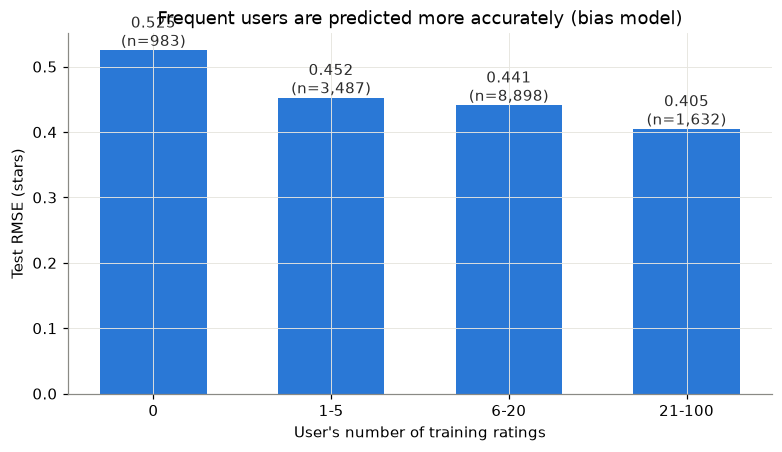

In [14]:
slices = pd.concat([error_slices(train, test, test_pred[n], n) for n in ['bias', 'item_cf', 'als_mf']],
                   ignore_index=True)
slices.to_csv(REPORTS/'C_error_slices.csv', index=False)
table = slices[slices.slice.isin(['UserID_history', 'WineID_history'])].pivot_table(
    index=['slice', 'group'], columns='model', values='rmse', sort=False)
table['rows'] = slices[(slices.model == 'bias') & slices.slice.isin(['UserID_history', 'WineID_history'])
                       ].set_index(['slice', 'group']).n
display(table.round(4))

fig, ax = plt.subplots(figsize=(7, 4), layout='constrained')
s = slices[(slices.slice == 'UserID_history') & (slices.model == 'bias')]
ax.bar(s.group, s.rmse, color=SERIES[0], width=0.6)
for x, (r, n) in enumerate(zip(s.rmse, s.n)):
    ax.annotate(f'{r:.3f}\n(n={n:,})', (x, r), xytext=(0, 3), textcoords='offset points', ha='center', color=INK)
ax.set(xlabel="User's number of training ratings", ylabel='Test RMSE (stars)',
       title='Frequent users are predicted more accurately (bias model)')
fig.savefig(FIGURES/'C_error_by_user_history.png', bbox_inches='tight'); plt.show()

## 5.2 Interpreting the bias parameters

$b_i$ is how much higher (or lower) a wine is rated than average after accounting for who rated it; $b_u$ is
how generous a user is. Only wines with at least 30 training ratings are listed, so the ranking is not driven by
a handful of ratings.

Highest wine biases


,b_i,ratings,WineName,Type,Country,RegionName
174184,1.025,509,Grange,Red,Australia,South Australia
112084,1.020,178,Oenothèque Brut Champagne,Sparkling,France,Champagne
111415,0.986,564,Pauillac (Premier Grand Cru Classé),Red,France,Pauillac
180330,0.961,74,IX Estate Red,Red,United States,Napa Valley
111395,0.955,820,Pauillac (Premier Grand Cru Classé),Red,France,Pauillac
112664,0.939,111,Meursault Blanc,White,France,Meursault
179855,0.915,122,Cabernet Sauvignon,Red,United States,Napa Valley
181280,0.915,33,Red Blend,Red,United States,Napa Valley


Lowest wine biases


,b_i,ratings,WineName,Type,Country,RegionName
100120,-1.180,51,Marcus James Cabernet Sauvignon,Red,Brazil,Serra Gaúcha
193719,-1.087,76,Retsina of Attica,White,Greece,Peloponnesos
155623,-1.049,103,Tempranillo,Red,Spain,Valdepeñas
162948,-0.899,90,Cabernet Sauvignon,Red,Chile,Central Valley (CL)
168002,-0.899,76,Malbec,Red,Argentina,Mendoza
162894,-0.886,76,Carmenérè,Red,Chile,Central Valley (CL)
174466,-0.884,60,Sauvignon Blanc,White,Australia,South Australia
163383,-0.874,41,Carmenere,Red,Chile,Central Valley (CL)


,wines,mean_b_i
Type,,
Rosé,83,-0.330
White,230,-0.163
Sparkling,98,-0.067
Red,506,-0.063
Dessert,58,0.066
Dessert/Port,25,0.096


Spearman correlation of wine bias with log(number of ratings): 0.083
User bias b_u: sd 0.195, 5th-95th percentile [-0.336, 0.282] stars


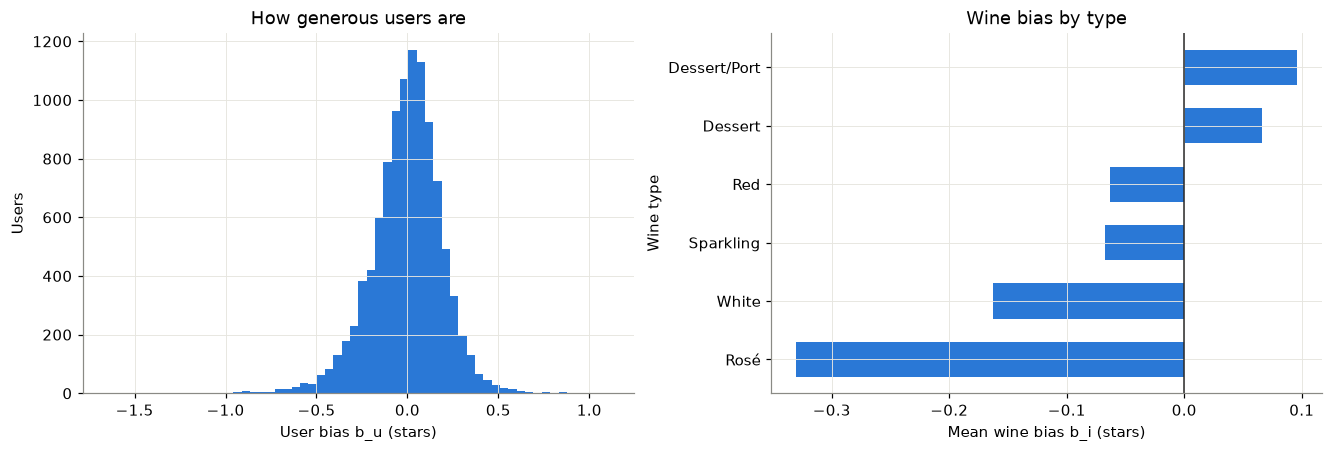

In [15]:
bias = final['bias']
wine_table = wines.set_index('WineID')[['WineName', 'Type', 'Country', 'RegionName']]
wb = pd.DataFrame({'b_i': bias.bi, 'ratings': bias.item_count}).join(wine_table)
supported = wb[wb.ratings >= 30].sort_values('b_i')
print('Highest wine biases'); display(supported.tail(8).iloc[::-1].round(3))
print('Lowest wine biases'); display(supported.head(8).round(3))
supported.to_csv(REPORTS/'C_wine_biases.csv')
by_type = wb.groupby('Type').agg(wines=('b_i', 'size'), mean_b_i=('b_i', 'mean')).sort_values('mean_b_i')
display(by_type.round(3))
by_type.to_csv(REPORTS/'C_wine_bias_by_type.csv')
rho = wb[['b_i']].assign(log_n=np.log(wb.ratings)).corr(method='spearman').iloc[0, 1]
print(f"Spearman correlation of wine bias with log(number of ratings): {rho:.3f}")
print(f"User bias b_u: sd {bias.bu.std():.3f}, 5th-95th percentile "
      f"[{bias.bu.quantile(.05):.3f}, {bias.bu.quantile(.95):.3f}] stars")

fig, ax = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')
ax[0].hist(bias.bu, bins=60, color=SERIES[0])
ax[0].set(xlabel='User bias b_u (stars)', ylabel='Users', title='How generous users are')
ax[1].barh(by_type.index, by_type.mean_b_i, color=SERIES[0], height=0.6)
ax[1].axvline(0, color=INK, linewidth=1)
ax[1].set(xlabel='Mean wine bias b_i (stars)', ylabel='Wine type', title='Wine bias by type')
fig.savefig(FIGURES/'C_bias_interpretation.png', bbox_inches='tight'); plt.show()

## 5.3 Do the latent factors find taste groups?

The validation-selected factors are shrunk close to zero, so for interpretation we use a less regularized
model ($k = 16$, $\lambda = 9$) whose factors are clearly non-zero. We project the wine vectors $q_i$ to 2D
with PCA and colour them by wine type, and measure how often a wine's 10 nearest neighbours in factor space share
its type or country, compared with random neighbours.

,label,k,observed_same_label,random_expected,largest_class_share
0,Type,10,0.380,0.374,0.557
1,Country,10,0.139,0.117,0.257


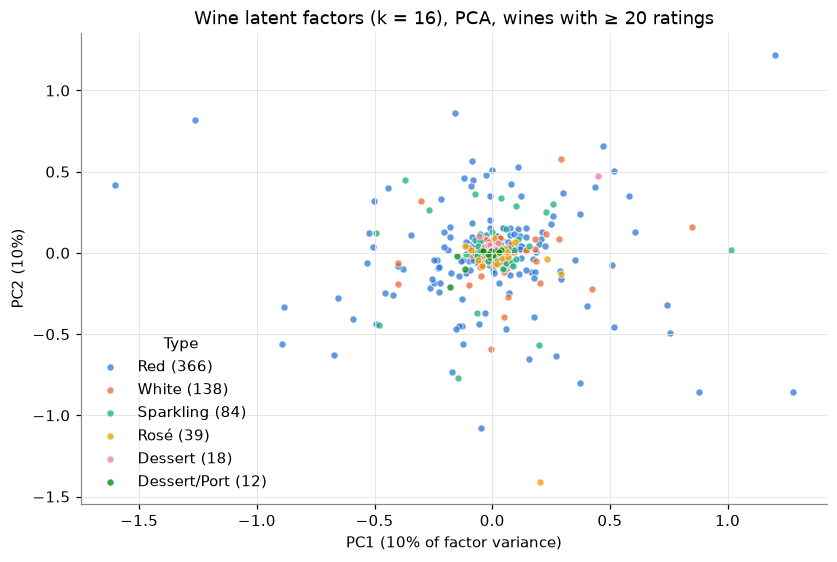

In [16]:
explore = ALSMF(16, 9, reg_user_bias=best_bias.reg_user, reg_item_bias=best_bias.reg_item, n_iter=10).fit(train)
q, _ = explore.wine_factors()
q = q[q.index.isin(bias.item_count[bias.item_count >= 20].index)]
centered = q - q.mean()
u_, s_, vt = np.linalg.svd(centered.to_numpy(), full_matrices=False)
coords = pd.DataFrame(u_[:, :2] * s_[:2], index=q.index, columns=['pc1', 'pc2']).join(wine_table)
explained = s_[:2]**2 / (s_**2).sum()
agreement = pd.DataFrame([
    dict(label='Type', **neighbour_type_agreement(q, wine_table.Type)),
    dict(label='Country', **neighbour_type_agreement(q, wine_table.Country)),
])
agreement.to_csv(REPORTS/'C_embedding_agreement.csv', index=False)
display(agreement.round(3))

fig, ax = plt.subplots(figsize=(7.5, 5), layout='constrained')
order = coords.Type.value_counts().index
for color, wine_type in zip(SERIES, order):
    g = coords[coords.Type == wine_type]
    ax.scatter(g.pc1, g.pc2, s=22, color=color, alpha=0.75, edgecolor='white', linewidth=0.6,
               label=f'{wine_type} ({len(g)})')
ax.set(xlabel=f'PC1 ({explained[0]:.0%} of factor variance)', ylabel=f'PC2 ({explained[1]:.0%})',
       title='Wine latent factors (k = 16), PCA, wines with ≥ 20 ratings')
ax.legend(title='Type', frameon=False, loc='best')
fig.savefig(FIGURES/'C_embedding_pca.png', bbox_inches='tight'); plt.show()

## 5.4 Is there stable personal taste to learn?

If users had stable personal tastes (e.g. "I like reds more than other people do"), a user's preference measured
on one half of their ratings should predict it on the other half. For users with at least 4 Red and 4 White
training ratings we randomly split each type's ratings in two halves, compute the user's Red-minus-White
**residual** (after removing user and wine biases) in each half, and correlate the halves across users.
A correlation near zero means the "personal preference" is mostly noise, and no CF model can learn it.

In [17]:
joined = join_metadata(train, wines)[['UserID', 'Type', 'Rating']].copy()
joined['residual'] = (train.Rating - bias.predict(train)).to_numpy()
rw = joined[joined.Type.isin(['Red', 'White'])].copy()
counts = rw.groupby(['UserID', 'Type']).size().unstack(fill_value=0)
eligible = counts[(counts.get('Red', 0) >= 4) & (counts.get('White', 0) >= 4)].index
rw = rw[rw.UserID.isin(eligible)].copy()
rng = np.random.default_rng(SEED)
reliability = []
for repeat in range(20):
    rw['half'] = rw.groupby(['UserID', 'Type']).residual.transform(
        lambda x: rng.permutation(len(x)) % 2)
    halves = rw.groupby(['UserID', 'half', 'Type']).residual.mean().unstack('Type')
    diff = (halves.Red - halves.White).unstack('half')
    reliability.append(pearsonr(diff[0], diff[1])[0])
reliability = np.array(reliability)
taste = dict(eligible_users=len(eligible), split_half_r_mean=float(reliability.mean()),
             split_half_r_min=float(reliability.min()), split_half_r_max=float(reliability.max()))
pd.Series(taste).to_frame('value').to_csv(REPORTS/'C_taste_reliability.csv')
print(f"Users with >= 4 Red and >= 4 White training ratings: {len(eligible):,}")
print(f"Split-half correlation of personal Red-minus-White preference: mean r = {reliability.mean():.3f} "
      f"(range {reliability.min():.3f} to {reliability.max():.3f} over 20 random splits)")

Users with >= 4 Red and >= 4 White training ratings: 1,536
Split-half correlation of personal Red-minus-White preference: mean r = 0.030 (range -0.019 to 0.080 over 20 random splits)


## 5.5 Summary table

Validation-selected configuration of each model, chronological test, and the random-split sensitivity check.

In [18]:
summary = results[['model', 'settings', 'rmse', 'mae']].merge(
    random_results[['model', 'rmse']].rename(columns={'rmse': 'random_split_rmse'}), on='model', how='left')
display(summary.round(4))
summary.to_csv(REPORTS/'C_summary.csv', index=False)

,model,settings,rmse,mae,random_split_rmse
0,global,repo reference,0.6123,0.4932,NaN
1,user_mean,repo reference,0.5878,0.4649,NaN
2,item_mean,repo reference,0.4785,0.3682,NaN
3,ridge_ids (repo),repo reference,0.4493,0.3401,NaN
4,bias,"reg_user=5, reg_item=2",0.4457,0.3356,0.4706
5,item_cf,"cosine, k=10, damping=1",0.4446,0.3342,0.4687
6,als_mf,"k=8, lambda=11",0.4460,0.3358,0.4707
7,surprise_svd,"k=4, reg=0.02, epochs=20",0.4457,0.3350,0.4760
8,surprise_svdpp,"k=4, reg=0.02, epochs=20",0.4457,0.3351,0.4758


## Findings (Person C)

See `reports/C_findings.md` for the written conclusions with the numbers from this run.